# QCNN - results analysis

## Setup and Data Preparation

Import libraries, configure the analysis, and load and validate training results. Compute summary statistics and define shared plotting styles and helpers to prepare the figures below.

In [ ]:
# import libraries
from pathlib import Path
import json
import math
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, PercentFormatter
from IPython import get_ipython
from IPython.display import display

# find the project root directory by looking for the training script
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "training" / "train.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Open the notebook from a directory inside the qcnn project.")

# print matplotlib plots inline in the notebook
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_rows", 30)
pd.set_option("display.max_columns", 16)

In [ ]:
MODELS = sorted(
    (p.stem for p in (PROJECT_ROOT / "models").glob("model[0-9]*.py") if p.stem[5:].isdigit()),
    key=lambda name: int(name[5:]),
)

# Select completed runs; available datasets also include mnist and organamnist.
DATASETS = ["fashion4_1", "fashion4_2", "fashion4_3"]
SEEDS = [11, 42, 59]

# Plot curves for this dataset/seed; both must be included in DATASETS/SEEDS.
TRAINING_DATASET = "fashion4_2"
TRAINING_SEED = 42

# plot settings
MODELS_PER_FIGURE = 6
CONFUSION_VIEW = "percent"  # "percent" or "counts" for confusion matrix view

RESULTS_DIR = PROJECT_ROOT / "results"

In [ ]:
# Utilities for reading saved training results.
def read_json(path):
    with Path(path).open(encoding="utf-8") as stream:
        return json.load(stream)

# load results of training runs and check for consistency
def load_results(results_dir, models, datasets, seeds):
    records, matrices, metadata, issues = [], {}, {}, []
    for dataset in datasets:
        for model in models:
            for seed in seeds:
                run = Path(results_dir) / model / dataset / f"seed{seed}"
                paths = [run / "config.json", run / "test.json"]
                if any(not path.is_file() for path in paths):
                    issues.append(f"{model}/{dataset}/seed{seed}: missing config.json or test.json")
                    continue
                try:
                    config, result = map(read_json, paths)
                    for record in (config, result):
                        if (record["model"], record["dataset"], record["seed"]) != (model, dataset, seed):
                            raise ValueError("inconsistent training run identity")
                    names, labels = tuple(result["class_names"]), tuple(result["original_labels"])
                    if config["class_names"] != list(names) or config["original_labels"] != list(labels):
                        raise ValueError("inconsistent class order between config and test")
                    matrix = np.asarray(result["confusion_matrix"], dtype=float)
                    accuracy = float(result["test_acc"])
                    best_epoch, epochs = int(result["best_epoch"]), int(result["n_epochs_trained"])
                    metadata[dataset] = (names, labels)
                    matrices[(model, dataset, seed)] = matrix
                    records.append({
                        "model": model, "dataset": dataset, "seed": seed,
                        "test_acc": accuracy, "test_accuracy_pct": 100 * accuracy,
                        "test_size": int(result["test_size"]), "best_epoch": best_epoch,
                        "n_epochs_trained": epochs, "n_params": int(result["n_params"]),
                        "encoding": config["encoding"], "ansatz": config["ansatz"],
                        "topology": config["topology"],
                    })
                except (KeyError, ValueError, TypeError) as exc:
                    issues.append(f"{model}/{dataset}/seed{seed}: {exc}")
    if issues:
        extra = f"\n... {len(issues) - 12} more issues" if len(issues) > 12 else ""
        raise RuntimeError(f"{len(issues)} missing or inconsistent training runs. Complete all selected runs before analysis.\n" + "\n".join(issues[:12]) + extra)
    runs = pd.DataFrame(records)
    if runs.groupby("model")[["encoding", "ansatz", "topology", "n_params"]].nunique().gt(1).any().any():
        raise ValueError("A model definition differs across the selected training runs.")
    return runs, matrices, metadata

# load training curves for a given dataset and seed with consistency checks
def load_training_curves(results_dir, runs, dataset, seed, models):
    curves = {}
    required = ["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "time_sec"]
    for model in models:
        path = Path(results_dir) / model / dataset / f"seed{seed}" / "metrics.csv"
        if not path.is_file():
            raise FileNotFoundError(f"Missing training curves: {path}")
        frame = pd.read_csv(path)
        if not set(required).issubset(frame.columns) or frame.empty:
            raise ValueError(f"Empty or incomplete metrics.csv: {path}")
        if not np.array_equal(frame.epoch.to_numpy(), np.arange(1, len(frame) + 1)):
            raise ValueError(f"Duplicate or missing epochs: {path}")
        record = runs[(runs.model == model) & (runs.dataset == dataset) & (runs.seed == seed)].iloc[0]
        if len(frame) != record.n_epochs_trained:
            raise ValueError(f"metrics.csv and test.json have different epoch counts: {path}")
        curves[model] = frame
    return curves

# run loading functions
runs, confusion_by_run, class_metadata = load_results(RESULTS_DIR, MODELS, DATASETS, SEEDS)
training_curves = load_training_curves(RESULTS_DIR, runs, TRAINING_DATASET, TRAINING_SEED, MODELS)

# display summary of loaded results
coverage = runs.groupby(["model", "dataset"]).seed.nunique().unstack().reindex(index=MODELS, columns=DATASETS)
print(f"{len(runs)} completed training runs; {len(training_curves)} curves loaded for {TRAINING_DATASET}, seed {TRAINING_SEED}.")
display(coverage.rename_axis(columns="Number of seeds per dataset"))
display(pd.DataFrame([{"dataset": d, "classes in output-label order 0-3": ", ".join(class_metadata[d][0])} for d in DATASETS]))

In [ ]:
# summarize test accuracy for each group
def summarize_accuracy(frame, keys):
    return frame.groupby(keys, sort=False).agg(
        mean_test_accuracy_pct=("test_accuracy_pct", "mean"),
        std_test_accuracy_pct=("test_accuracy_pct", "std"),
        n_runs=("test_accuracy_pct", "size"),
    ).reset_index()


# aggregate accuracy by dataset and across all datasets
accuracy_by_dataset = summarize_accuracy(runs, ["model", "dataset"])
accuracy_global = summarize_accuracy(runs, ["model"])

# average confusion matrices and collect per-seed class recall
class_rows, mean_confusions = [], {}
for dataset in DATASETS:
    names, original_labels = class_metadata[dataset]
    for model in MODELS:
        counts = np.stack([confusion_by_run[(model, dataset, seed)] for seed in SEEDS])
        # normalize each seed by true-class row before averaging
        percentages = counts / counts.sum(axis=2, keepdims=True) * 100
        mean_counts, mean_percent = counts.mean(axis=0), percentages.mean(axis=0)
        mean_confusions[(model, dataset)] = {"counts": mean_counts, "percent": mean_percent}
        for seed_index, seed in enumerate(SEEDS):
            for label, name in enumerate(names):
                class_rows.append({
                    "model": model, "dataset": dataset, "seed": seed, "output_label": label,
                    "original_label": original_labels[label], "class_name": name,
                    "support": int(counts[seed_index, label].sum()),
                    "correct": int(counts[seed_index, label, label]),
                    "class_accuracy_pct": percentages[seed_index, label, label],
                })

# summarize class recall across seeds (sample standard deviation)
class_by_seed = pd.DataFrame(class_rows)
class_summary = class_by_seed.groupby(
    ["model", "dataset", "output_label", "original_label", "class_name"], sort=False
).agg(
    mean_class_accuracy_pct=("class_accuracy_pct", "mean"),
    std_class_accuracy_pct=("class_accuracy_pct", "std"),
    mean_support=("support", "mean"), n_seeds=("seed", "size"),
).reset_index()

# display mean test accuracy for each model and dataset
display(accuracy_by_dataset.pivot(index="model", columns="dataset", values="mean_test_accuracy_pct").reindex(MODELS).round(2))

In [ ]:
# apply a shared style to all figures
plt.rcParams.update({
    "figure.dpi": 110, "font.family": "DejaVu Sans",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelcolor": "#263445", "text.color": "#263445",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.facecolor": "#F3F6FA", "figure.facecolor": "white",
    "grid.color": "white", "grid.linewidth": 1.2,
    "legend.frameon": False,
})
# assign colors and markers
DATASET_PALETTE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]
DATASET_COLORS = {name: DATASET_PALETTE[i % len(DATASET_PALETTE)] for i, name in enumerate(DATASETS)}
CLASS_COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
SEED_MARKERS = ["o", "s", "^", "D", "P", "X"]
# use readable display for better visualization of encoding types, connectivity topologies and ansatzes
ENCODING_LABELS = {"e1": "VITTORI ENC.", "e3": "AMPLITUDE"}
TOPOLOGY_LABELS = {"benchmark": "STANDARD"}


# split models into groups for each figure
def model_groups():
    for start in range(0, len(MODELS), MODELS_PER_FIGURE):
        yield MODELS[start:start + MODELS_PER_FIGURE]


# create one panel per model and hide unused panels
def panel_grid(models, height=3.5):
    cols = min(3, len(models))
    rows = math.ceil(len(models) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4.7 * cols, height * rows),
                             squeeze=False, layout="constrained")
    active = list(axes.flat[:len(models)])
    for ax in axes.flat[len(models):]:
        ax.set_visible(False)
    return fig, active


# round accuracy limits with padding, bounded by 0 and 100
def accuracy_limits(values):
    values = np.asarray(values, dtype=float)
    low = max(0, math.floor((values.min() - 3) / 5) * 5)
    high = min(100, math.ceil((values.max() + 3) / 5) * 5)
    return (low, high) if low < high else (0, 100)


# use common axis limits to compare models consistently
TEST_LIMITS = accuracy_limits(runs.test_accuracy_pct)
TRAIN_MAX_EPOCH = max(int(frame.epoch.max()) for frame in training_curves.values())
TRAIN_ACC_LIMITS = accuracy_limits(np.concatenate([frame[["train_acc", "val_acc"]].to_numpy().ravel() * 100 for frame in training_curves.values()]))
TRAIN_LOSS_MAX = max(frame[["train_loss", "val_loss"]].to_numpy().max() for frame in training_curves.values()) * 1.05

## Training Plots
The following plots show training and validation accuracy and loss for all models, using `TRAINING_DATASET` and `TRAINING_SEED` from the configuration cell. Both must belong to the selected `DATASETS` and `SEEDS`.

Panel titles show encoding / ansatz / connectivity. The dashed line marks the best checkpoint epoch selected by validation accuracy.

In [ ]:
def plot_training_group(models, metric):
    fig, axes = panel_grid(models, height=3.1)
    is_accuracy = metric == "acc"
    scale = 100 if is_accuracy else 1
    selected = runs[(runs.dataset == TRAINING_DATASET) & (runs.seed == TRAINING_SEED)].set_index("model")
    for ax, model in zip(axes, models):
        frame = training_curves[model]
        ax.plot(frame.epoch, frame[f"train_{metric}"] * scale, color="#0072B2", lw=2, label="Train")
        ax.plot(frame.epoch, frame[f"val_{metric}"] * scale, color="#D55E00", lw=2, label="Validation")
        best = int(selected.loc[model, "best_epoch"])
        ax.axvline(best, color="#526477", ls="--", lw=1.2)
        value = float(frame.loc[frame.epoch == best, f"val_{metric}"].iloc[0]) * scale
        ax.scatter(best, value, color="#D55E00", edgecolors="white", s=45, zorder=4)
        encoding = selected.loc[model, "encoding"]
        topology = selected.loc[model, "topology"]
        encoding_label = ENCODING_LABELS.get(encoding, encoding.upper())
        topology_label = TOPOLOGY_LABELS.get(topology, topology.upper())
        ax.set_title(f"{encoding_label} / {selected.loc[model, 'ansatz'].upper()} / {topology_label}", loc="left", fontsize=11)
        ax.set_xlim(0.7, max(1.3, TRAIN_MAX_EPOCH + 0.3))
        ax.set_ylim(TRAIN_ACC_LIMITS if is_accuracy else (0, max(0.01, TRAIN_LOSS_MAX)))
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy (%)" if is_accuracy else "Cross-entropy")
        ax.set_axisbelow(True)
        ax.grid(alpha=0.9)
    handles, labels = axes[0].get_legend_handles_labels()
    handles.append(Line2D([], [], color="#526477", ls="--", label="Best epoch"))
    fig.legend(handles=handles, loc="outside lower center", ncol=3)
    title = "Accuracy" if is_accuracy else "Loss"
    fig.suptitle(f"{title} during training | {TRAINING_DATASET} | seed {TRAINING_SEED}", fontsize=16)
    return fig


for group in model_groups():
    for metric in ("acc", "loss"):
        figure = plot_training_group(group, metric)
        display(figure)
        plt.close(figure)

## Confusion Matrices

The following plots show the confusion matrices obtained for each model and dataset. The title of each panel shows the model name and its mean test accuracy across the selected seeds for that dataset.  
Test sets are balanced across the four classes: 2,800 images for Fashion-MNIST and 2,000 for MNIST/OrganAMNIST with the default settings. Actual test sizes are read from the saved results. The reported values are averaged over the **selected seeds** (three by default). Rows represent the **true classes**, while columns represent the **predicted classes**.

Set `CONFUSION_VIEW` in the configuration cell to `"percent"` for percentages or `"counts"` for sample counts.

In `percent` mode, each confusion matrix is first normalized row-wise for each seed and then averaged across the selected seeds. 

In `counts` mode, the matrices instead report the mean number of samples across the selected seeds.

In [ ]:
def plot_confusion_group(models, dataset):
    fig, axes = panel_grid(models, height=4.0)
    names = class_metadata[dataset][0]
    upper = 100 if CONFUSION_VIEW == "percent" else max(mean_confusions[(m, dataset)]["counts"].max() for m in MODELS)
    for ax, model in zip(axes, models):
        matrix = mean_confusions[(model, dataset)][CONFUSION_VIEW]
        heat = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=upper, aspect="equal")
        mean_accuracy = accuracy_by_dataset.loc[(accuracy_by_dataset.model == model) & (accuracy_by_dataset.dataset == dataset), "mean_test_accuracy_pct"].iloc[0]
        ax.set_title(f"{model} | test {mean_accuracy:.2f}%", loc="left", fontsize=11)
        ax.set_xticks(range(4), names, rotation=35, ha="right", fontsize=8)
        ax.set_yticks(range(4), names, fontsize=8)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("True class")
        for true in range(4):
            for predicted in range(4):
                value = matrix[true, predicted]
                ax.text(predicted, true, f"{value:.1f}", ha="center", va="center",
                        color="white" if value > 0.55 * upper else "#263445",
                        fontsize=10, fontweight="bold" if true == predicted else "normal")
    fig.colorbar(heat, ax=axes, shrink=0.8, label="Mean percentage per true class (%)" if CONFUSION_VIEW == "percent" else "Mean count")
    fig.suptitle(f"Confusion matrices | {dataset} ", fontsize=16)
    return fig


for dataset in DATASETS:
    for group in model_groups():
        figure = plot_confusion_group(group, dataset)
        display(figure)
        plt.close(figure)

### Model5, model6 and model25 across the selected datasets

The following comparison cell explicitly selects these three models. If `MODELS` contains a different selection, update the list passed to `plot_model_confusions` to use only loaded models.

In [ ]:
def plot_model_confusions(models, datasets):
    fig, axes = plt.subplots(len(models), len(datasets),
                             figsize=(4.7 * len(datasets), 4.4 * len(models)),
                             squeeze=False, layout="constrained")
    fig.get_layout_engine().set(hspace=0.12)
    upper = 100 if CONFUSION_VIEW == "percent" else max(
        mean_confusions[(model, dataset)]["counts"].max()
        for model in models for dataset in datasets
    )
    for ax, (model, dataset) in zip(
        axes.flat, ((model, dataset) for model in models for dataset in datasets)
    ):
        names = class_metadata[dataset][0]
        matrix = mean_confusions[(model, dataset)][CONFUSION_VIEW]
        heat = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=upper, aspect="equal")
        mean_accuracy = accuracy_by_dataset.loc[
            (accuracy_by_dataset.model == model) & (accuracy_by_dataset.dataset == dataset),
            "mean_test_accuracy_pct",
        ].iloc[0]
        ax.set_title(f"{model} | {dataset} | test {mean_accuracy:.2f}%", loc="left", fontsize=11)
        ax.set_xticks(range(len(names)), names, rotation=35, ha="right", fontsize=8)
        ax.set_yticks(range(len(names)), names, fontsize=8)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("True class")
        for true in range(len(names)):
            for predicted in range(len(names)):
                value = matrix[true, predicted]
                ax.text(predicted, true, f"{value:.1f}", ha="center", va="center",
                        color="white" if value > 0.55 * upper else "#263445",
                        fontsize=10, fontweight="bold" if true == predicted else "normal")
    fig.colorbar(heat, ax=list(axes.flat), shrink=0.8,
                 label="Mean percentage per true class (%)" if CONFUSION_VIEW == "percent" else "Mean count")
    fig.suptitle("Confusion matrices | " + ", ".join(models) + "\n", fontsize=16)
    return fig


confusion_comparison_figure = plot_model_confusions(
    ["model5", "model6", "model25"],
    DATASETS,
)
display(confusion_comparison_figure)
plt.close(confusion_comparison_figure)

## Accuracy Box Plot

The following plots compare the test accuracy obtained by the different models, with a separate figure for each dataset and model group. Each box plot summarizes the distribution across the selected random seeds (three by default), while the overlaid points represent the individual runs, using a different marker for each seed. The red diamond indicates the mean test accuracy across the selected seeds.

In [ ]:
# shared box plot function for per-dataset and all-dataset comparisons
# dataset selects one task; None pools all selected dataset-seed runs
def plot_accuracy_boxes(models, dataset=None):
    # filter runs and collect test accuracies for each model
    selected_datasets = [dataset] if dataset else DATASETS
    subset = runs[runs.model.isin(models) & runs.dataset.isin(selected_datasets)]
    positions = np.arange(1, len(models) + 1)
    values = [subset.loc[subset.model == model, "test_accuracy_pct"].to_numpy() for model in models]
    fig, ax = plt.subplots(figsize=(13, 6.2), layout="constrained")
    # box: Q1-Q3; dark line: median; red diamond: mean
    # whiskers: observed extremes within 1.5 IQR of the box edges
    # individual runs below also show values beyond the whiskers
    boxes = ax.boxplot(
        values, positions=positions, widths=0.58, patch_artist=True,
        showmeans=True, showfliers=False, whis=1.5,
        meanprops={"marker": "D", "markerfacecolor": "#D55E00", "markeredgecolor": "white", "markersize": 8, "zorder": 5},
        medianprops={"color": "#263445", "linewidth": 1.6},
        whiskerprops={"color": "#72849A"}, capprops={"color": "#72849A"},
        boxprops={"facecolor": "#DCEAF7", "edgecolor": "#72849A", "linewidth": 1.2},
    )
    # overlay every run: dataset colors and seed markers
    for position, model, data in zip(positions, models, values):
        for dataset_index, current_dataset in enumerate(selected_datasets):
            for seed_index, seed in enumerate(SEEDS):
                value = subset.loc[(subset.model == model) & (subset.dataset == current_dataset) & (subset.seed == seed), "test_accuracy_pct"].iloc[0]
                # separate points horizontally without changing their accuracy
                offset = (dataset_index - (len(selected_datasets) - 1) / 2) * 0.16
                offset += (seed_index - (len(SEEDS) - 1) / 2) * (0.05 if dataset is None else 0.09)
                ax.scatter(position + offset, value, color=DATASET_COLORS[current_dataset],
                           marker=SEED_MARKERS[seed_index % len(SEED_MARKERS)], s=42,
                           edgecolors="white", linewidths=0.7, zorder=4)
        # label the mean, weighting each dataset-seed run equally
        ax.annotate(f"{np.mean(data):.2f}%", (position, np.mean(data)),
                    xytext=(0, 14), textcoords="offset points", ha="center", fontsize=10,
                    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1.5})
    # use common accuracy limits for comparisons across figures
    ax.set_xticks(positions, models)
    ax.set_ylim(TEST_LIMITS)
    ax.set_ylabel("Test accuracy (%)")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.9)
    # explain seed markers, dataset colors when pooled, and the mean
    mean_handle = Line2D([], [], ls="", marker="D", markerfacecolor="#D55E00", markeredgecolor="white", markersize=8, label="Mean")
    handles = [Line2D([], [], ls="", marker=SEED_MARKERS[i % len(SEED_MARKERS)], color="#53677E", markersize=7, label=f"Seed {seed}") for i, seed in enumerate(SEEDS)]
    if dataset is None:
        handles = [Patch(color=DATASET_COLORS[d], label=d) for d in DATASETS] + handles
    handles.append(mean_handle)
    fig.legend(handles=handles, loc="outside lower center", ncol=min(4, len(handles)))
    # adapt the title to the selected comparison
    title = f"{dataset} | {len(SEEDS)} seeds per model" if dataset else f"All selected datasets"
    fig.suptitle(f"Test accuracy | {title}", fontsize=15)
    return fig


for dataset in DATASETS:
    for group in model_groups():
        # create and display each per-dataset comparison
        figure = plot_accuracy_boxes(group, dataset=dataset)
        display(figure)
        plt.close(figure)

## Accuracy Box Plot Across All Selected Four-Class Datasets
Each box summarizes the test accuracy of a model across all selected datasets and random seeds, providing an overall view of both its performance and variability across different class subsets and random initializations. 
The diamond indicates the global mean test accuracy, computed by assigning equal weight to each dataset-seed combination. The overlaid points correspond to the individual runs, with **colors identifying the different datasets** and **markers identifying the random seeds**.

In [ ]:
display(accuracy_global.set_index("model").reindex(MODELS).round(2))
for group in model_groups():
    figure = plot_accuracy_boxes(group)
    display(figure)
    plt.close(figure)

## Comparative Accuracy Table

The following table compares test accuracy across all selected models and datasets, reporting **mean ± sample standard deviation (%)** across the selected seeds. Models are grouped by connectivity and encoding, then ordered by ansatz.

Blue names indicate connectivity types, red names indicate ansatzes, and green names indicate encodings, as summarized in the legend. **Bold values** highlight the highest mean accuracy for each dataset, including ties at the displayed precision.

In [ ]:
# build a compact table ordered by topology, encoding, and ansatz
def plot_thesis_accuracy_table(frame, summary, datasets):
    topology_order = {"spatial_diag": 0, "benchmark": 1}
    encoding_order = {"reupload": 0, "e1": 1, "e3": 2}
    ansatz_order = {"hur6": 0, "hur8": 1, "hur9": 2, "custom": 3}
    metadata = frame.drop_duplicates("model").copy()
    for column, order in (("topology", topology_order), ("encoding", encoding_order),
                          ("ansatz", ansatz_order)):
        metadata[f"{column}_order"] = metadata[column].map(order).fillna(len(order))
    metadata["model_number"] = metadata.model.str.removeprefix("model").astype(int)
    metadata = metadata.sort_values(
        ["topology_order", "encoding_order", "ansatz_order", "model_number"]
    )
    panels = list(metadata.groupby("topology", sort=False))
    encodings = list(metadata.encoding.unique())
    rows_per_encoding = {encoding: max(int(group.encoding.eq(encoding).sum())
                                       for _, group in panels) for encoding in encodings}
    total_rows = sum(1 + rows_per_encoding[encoding] for encoding in encodings)
    results = summary.set_index(["model", "dataset"])
    best_means = summary.groupby("dataset").mean_test_accuracy_pct.max().round(2)
    name_colors = {"Connectivity type": "#0072B2", "Ansatz": "#C0392B", "Encoding": "#007A4D"}

    # one shared grid aligns encoding bands across the topology groups
    fig, ax = plt.subplots(figsize=(3.6 * len(panels), 0.225 * total_rows + 1.1))
    fig.subplots_adjust(left=0.025, right=0.985, top=0.92, bottom=0.14)
    ax.set_xlim(0, 1)
    ax.set_ylim(total_rows - 0.1, -2.7)
    ax.axis("off")
    gap = 0.04
    panel_width = (1 - gap * (len(panels) - 1)) / len(panels)
    metric_x = 0.32 + (np.arange(len(datasets)) + 0.5) * 0.68 / len(datasets)
    for panel_index, (topology, group) in enumerate(panels):
        left = panel_index * (panel_width + gap)
        topology_label = TOPOLOGY_LABELS.get(topology, topology.upper())
        ax.text(left + panel_width / 2, -2.05, topology_label, color=name_colors["Connectivity type"],
                fontsize=8.3, fontweight="bold", ha="center", va="center")
        ax.text(left + 0.02 * panel_width, -1.0, "Model", fontsize=7.5, fontweight="bold", va="center")
        ax.text(left + 0.18 * panel_width, -1.0, "Ansatz", fontsize=7.5, fontweight="bold", va="center")
        for x, dataset in zip(metric_x, datasets):
            ax.text(left + panel_width * x, -1.0, dataset, fontsize=7.3, fontweight="bold", ha="center", va="center")
        ax.hlines(-0.55, left, left + panel_width, color="#526477", linewidth=0.7)
    row = 0
    for encoding in encodings:
        # center an encoding header within each topology group
        header_row = row
        encoding_label = ENCODING_LABELS.get(encoding, encoding.upper())
        row += 1
        for panel_index, (topology, group) in enumerate(panels):
            left = panel_index * (panel_width + gap)
            ax.axhspan(header_row - 0.42, header_row + 0.42, xmin=left, xmax=left + panel_width,
                       color="#EDF1F5", zorder=0)
            ax.text(left + panel_width / 2, header_row, encoding_label, color=name_colors["Encoding"],
                    fontsize=7.7, fontweight="bold", ha="center", va="center")
            block = group[group.encoding.eq(encoding)]
            for offset, record in enumerate(block.itertuples()):
                y = row + offset
                ax.text(left + 0.02 * panel_width, y, record.model, fontsize=7.2, va="center")
                ax.text(left + 0.18 * panel_width, y, record.ansatz.upper(),
                        color=name_colors["Ansatz"], fontsize=7.2, va="center")
                for x, dataset in zip(metric_x, datasets):
                    result = results.loc[(record.model, dataset)]
                    mean = result.mean_test_accuracy_pct
                    std = result.std_test_accuracy_pct
                    value = f"{mean:.2f}±{std:.2f}" if pd.notna(std) else f"{mean:.2f}"
                    # bold identifies the highest displayed mean for each dataset
                    weight = "bold" if round(mean, 2) == best_means.loc[dataset] else "normal"
                    ax.text(left + panel_width * x, y, value, fontsize=7.2, fontweight=weight,
                            ha="center", va="center")
        row += rows_per_encoding[encoding]
    ax.hlines(row - 0.45, 0, 1, color="#526477", linewidth=0.7)
    fig.suptitle("Mean test accuracy with standard deviation", fontsize=10, fontweight="bold", y=0.99)
    # explain the name colors below the table
    handles = [Patch(facecolor=color, label=label) for label, color in name_colors.items()]
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.055),
               ncol=3, fontsize=7, frameon=False, handlelength=1, borderaxespad=0)
    return fig


# display the compact table in the notebook
thesis_figure = plot_thesis_accuracy_table(runs, accuracy_by_dataset, DATASETS)
display(thesis_figure)
plt.close(thesis_figure)

## Accuracy Comparison Across All Selected Datasets

The following horizontal bar charts compare mean test accuracy across all selected dataset-seed combinations, equally weighted (nine runs per model by default), using the same data as the pooled box plots. The two panels separate connectivity types; each encoding uses the same color family, with a darker shade for SPATIAL_DIAG and a lighter shade for STANDARD. Models are ordered by ansatz within each encoding group.

Bar lengths show the **mean**, error bars show **±1 sample standard deviation**, and numeric labels report **mean ± SD (%)**.

In [ ]:
# Compare the same pooled dataset/seed runs used by the global box plots.
def plot_all_subsets_accuracy(frame, summary):
    from matplotlib.colors import to_rgb

    topology_order = {"spatial_diag": 0, "benchmark": 1}
    encoding_order = {"reupload": 0, "e1": 1, "e3": 2}
    ansatz_order = {"hur6": 0, "hur8": 1, "hur9": 2, "custom": 3}
    encoding_colors = {"reupload": "#0072B2", "e1": "#B94E00", "e3": "#007A4D"}
    data = frame.drop_duplicates("model")[["model", "topology", "encoding", "ansatz"]]
    data = data.merge(summary, on="model", validate="one_to_one")
    for column, order in (("topology", topology_order), ("encoding", encoding_order),
                          ("ansatz", ansatz_order)):
        data[f"{column}_order"] = data[column].map(order).fillna(len(order))
    data["model_number"] = data.model.str.removeprefix("model").astype(int)
    data = data.sort_values(["topology_order", "encoding_order", "ansatz_order", "model_number"])
    panels = list(data.groupby("topology", sort=False))
    encodings = list(data.encoding.unique())

    # align encoding groups and leave a small gap between them
    group_rows, row = {}, 0
    for encoding in encodings:
        group_rows[encoding] = row
        row += max(int(group.encoding.eq(encoding).sum()) for _, group in panels) + 1.3
    best_mean = data.mean_test_accuracy_pct.max().round(2)
    upper_error = data.mean_test_accuracy_pct + data.std_test_accuracy_pct.fillna(0)
    xmax = max(100, math.ceil(upper_error.max() / 10) * 10)
    fig, axes = plt.subplots(1, len(panels), figsize=(3.8 * len(panels), 0.225 * row + 0.8),
                             squeeze=False)
    fig.subplots_adjust(left=0.14, right=0.985, top=0.86, bottom=0.07, wspace=0.55)
    for ax, (topology, group) in zip(axes.flat, panels):
        ticks, labels, weights = [], [], []
        ax.set_facecolor("white")
        for encoding in encodings:
            block = group[group.encoding.eq(encoding)]
            if block.empty:
                continue
            header_y = group_rows[encoding]
            positions = header_y + 1 + np.arange(len(block))
            # use the same hue with distinct shades for the two topologies
            base_color = encoding_colors.get(encoding, "#607080")
            color = base_color if topology == "spatial_diag" else tuple(
                0.45 * channel + 0.55 for channel in to_rgb(base_color)
            )
            value_color = "white" if topology == "spatial_diag" else "#263445"
            ax.axhspan(header_y - 0.35, positions[-1] + 0.5, color="#F3F6FA", zorder=0)
            ax.text(0.02, header_y, ENCODING_LABELS.get(encoding, encoding.upper()),
                    transform=ax.get_yaxis_transform(), color=base_color,
                    fontsize=7.5, fontweight="bold", va="center")

            # bar lengths show means; whiskers show one sample SD
            ax.barh(positions, block.mean_test_accuracy_pct, height=0.62, color=color,
                    xerr=block.std_test_accuracy_pct.fillna(0), capsize=2.5, zorder=3,
                    error_kw={"ecolor": "#263445", "elinewidth": 0.9, "capthick": 0.9})
            for y, record in zip(positions, block.itertuples()):
                weight = "bold" if round(record.mean_test_accuracy_pct, 2) == best_mean else "normal"
                value = f"{record.mean_test_accuracy_pct:.2f}"
                if pd.notna(record.std_test_accuracy_pct):
                    value += f" ± {record.std_test_accuracy_pct:.2f}"
                ax.text(3, y, value, color=value_color, fontsize=7, fontweight=weight,
                        va="center", zorder=4)
                ticks.append(y)
                labels.append(f"{record.model} | {record.ansatz.upper()}")
                weights.append(weight)

        ax.set_yticks(ticks, labels, fontsize=7.2)
        for label, weight in zip(ax.get_yticklabels(), weights):
            label.set_fontweight(weight)
        ax.tick_params(axis="y", length=0, pad=5)
        ax.tick_params(axis="x", labelsize=7, length=0)
        ax.set_xlim(0, xmax)
        ax.set_xticks(np.arange(0, xmax + 1, 25))
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
        ax.set_ylim(row - 0.25, -0.65)
        ax.set_axisbelow(True)
        ax.grid(axis="x", color="#DCE3EB", linewidth=0.65)
        ax.set_title(TOPOLOGY_LABELS.get(topology, topology.upper()), fontsize=9,
                     fontweight="bold", color="#263445", pad=9)

    fig.suptitle("Test accuracy with standard deviation (%)| All subsets summary", fontsize=10.5, fontweight="bold", y=0.98)
    return fig


# Display the selected models without saving files.
all_subsets_summary = accuracy_global.copy()
all_subsets_figure = plot_all_subsets_accuracy(runs, all_subsets_summary)
display(all_subsets_figure)
plt.close(all_subsets_figure)

## Model17 on MNIST and OrganAMNIST

Mean test accuracy with sample standard deviation and individual runs for seeds **11, 42, 59**. Confusion matrices show mean row-normalized percentages (rows: true classes; columns: predictions). Use `confusion_view="counts"` for mean counts.

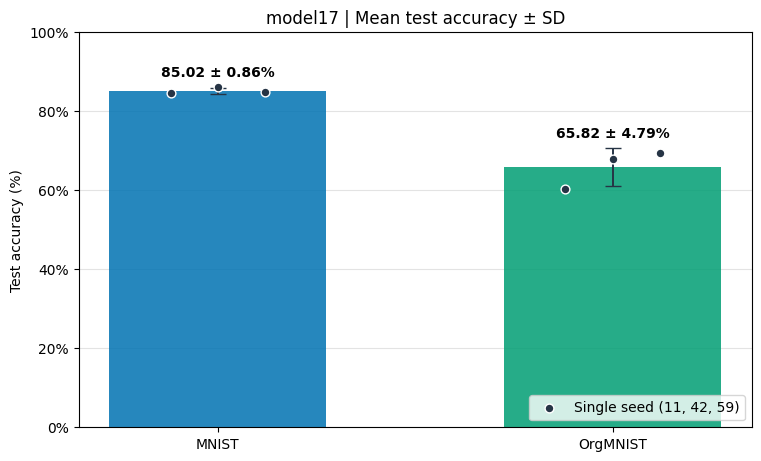

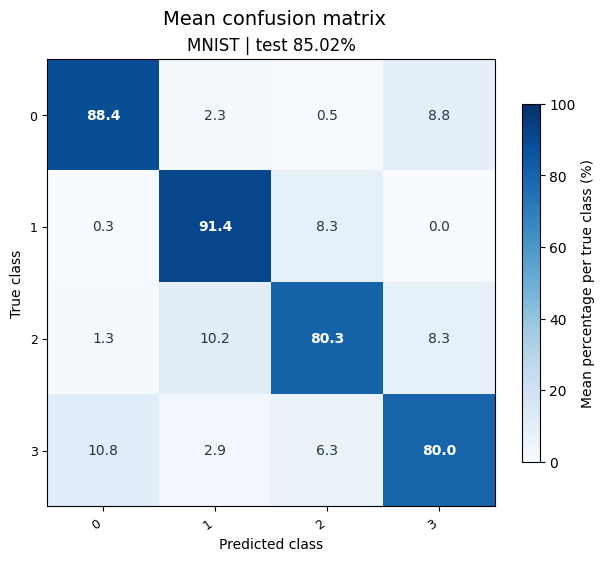

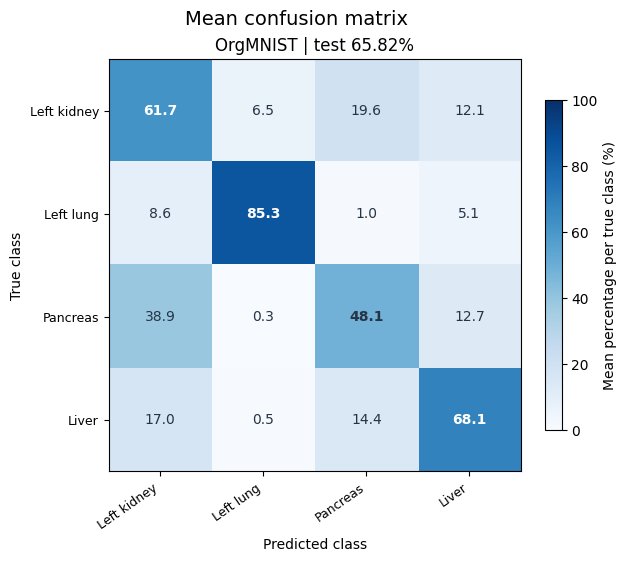

In [5]:
# Self-contained analysis of model17 on the two additional datasets.
def plot_model17_extra_datasets(confusion_view="percent"):
    import json
    from pathlib import Path

    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.ticker import PercentFormatter

    if confusion_view not in {"percent", "counts"}:
        raise ValueError('confusion_view must be "percent" or "counts".')
    root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / "training" / "train.py").is_file()), None)
    if root is None:
        raise RuntimeError("Open the notebook from a directory inside the qcnn project.")

    datasets = ("mnist", "organamnist")
    titles = ("MNIST", "OrgMNIST")
    seeds = (11, 42, 59)
    colors = ("#0072B2", "#009E73")
    accuracies, confusions, class_names = [], [], []
    for dataset in datasets:
        results = []
        for seed in seeds:
            result_path = root / "results" / "model17" / dataset / f"seed{seed}" / "test.json"
            with result_path.open(encoding="utf-8") as stream:
                result = json.load(stream)
            if (result["model"], result["dataset"], result["seed"]) != ("model17", dataset, seed):
                raise ValueError(f"Inconsistent run identity: {result_path}")
            results.append(result)
        names = results[0]["class_names"]
        if any((r["class_names"], r["original_labels"]) !=
               (names, results[0]["original_labels"]) for r in results):
            raise ValueError(f"Inconsistent class order across seeds: {dataset}")
        counts = np.asarray([r["confusion_matrix"] for r in results], dtype=float)
        if counts.shape != (len(seeds), len(names), len(names)):
            raise ValueError(f"Unexpected confusion matrix shape: {dataset}")
        percentages = np.divide(counts * 100, counts.sum(axis=2, keepdims=True),
                                out=np.zeros_like(counts), where=counts.sum(axis=2, keepdims=True) != 0)
        accuracies.append([100 * float(r["test_acc"]) for r in results])
        confusions.append((percentages if confusion_view == "percent" else counts).mean(axis=0))
        if dataset == "organamnist":
            english_names = {4: "Left kidney", 7: "Left lung", 9: "Pancreas", 6: "Liver"}
            names = [english_names[label] for label in results[0]["original_labels"]]
        class_names.append(names)

    accuracies = np.asarray(accuracies)
    means = accuracies.mean(axis=1)
    stds = accuracies.std(axis=1, ddof=1)
    fig, ax = plt.subplots(figsize=(7.5, 4.5), layout="constrained")
    ax.bar(np.arange(len(datasets)), means, yerr=stds, capsize=6,
           color=colors, width=0.55, alpha=0.85,
           error_kw={"ecolor": "#263445", "elinewidth": 1.4})
    for index, (mean, std, values) in enumerate(zip(means, stds, accuracies)):
        ax.scatter(index + np.linspace(-0.12, 0.12, len(seeds)), values,
                   color="#263445", edgecolors="white", s=40, zorder=3,
                   label="Single seed (11, 42, 59)" if index == 0 else None)
        ax.text(index, mean + std + 2, f"{mean:.2f} ± {std:.2f}%",
                ha="center", va="bottom", fontweight="bold")
    ax.set_xticks(np.arange(len(datasets)), titles)
    ax.set_ylim(0, 100)
    ax.set_ylabel("Test accuracy (%)")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.set_title("model17 | Mean test accuracy ± SD")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.35)
    ax.legend(loc="lower right")
    plt.show()
    plt.close(fig)

    upper = 100 if confusion_view == "percent" else max(matrix.max() for matrix in confusions)
    for title, names, matrix, mean in zip(titles, class_names, confusions, means):
        fig, ax = plt.subplots(figsize=(6.5, 5.5), layout="constrained")
        heat = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=upper, aspect="equal")
        ax.set_title(f"{title} | test {mean:.2f}%")
        ax.set_xticks(range(len(names)), names, rotation=35, ha="right", fontsize=9)
        ax.set_yticks(range(len(names)), names, fontsize=9)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("True class")
        ax.grid(False)
        for true in range(len(names)):
            for predicted in range(len(names)):
                value = matrix[true, predicted]
                ax.text(predicted, true, f"{value:.1f}", ha="center", va="center",
                        color="white" if value > 0.55 * upper else "#263445",
                        fontweight="bold" if true == predicted else "normal")
        fig.colorbar(heat, ax=ax, shrink=0.8,
                     label="Mean percentage per true class (%)" if confusion_view == "percent" else "Mean count")
        fig.suptitle("Mean confusion matrix", fontsize=14)
        plt.show()
        plt.close(fig)


plot_model17_extra_datasets(confusion_view="percent")